<a href="https://colab.research.google.com/github/aayushrouniyarcs24-cmd/BIS-LAB-1BF24CS010-/blob/main/Cuckoo_Search.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

CD-CSA Iteration: 50, Coverage: 80.46%
CD-CSA Iteration: 100, Coverage: 85.31%
CD-CSA Iteration: 150, Coverage: 88.01%
CD-CSA Iteration: 200, Coverage: 88.83%
CD-CSA Iteration: 250, Coverage: 89.75%
CD-CSA Iteration: 300, Coverage: 90.58%
CD-CSA Iteration: 350, Coverage: 90.98%
CD-CSA Iteration: 400, Coverage: 91.26%
CD-CSA Iteration: 450, Coverage: 91.90%
CD-CSA Iteration: 500, Coverage: 92.71%

========== COVERAGE RESULTS ==========
Initial Coverage: 67.77 %
Optimized Coverage: 92.71000000000001 %
Execution Time: 412.82910561561584 seconds


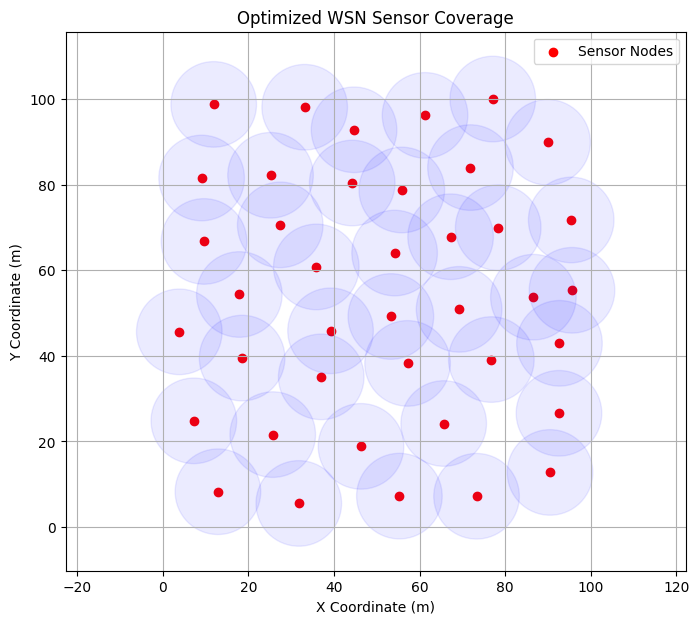

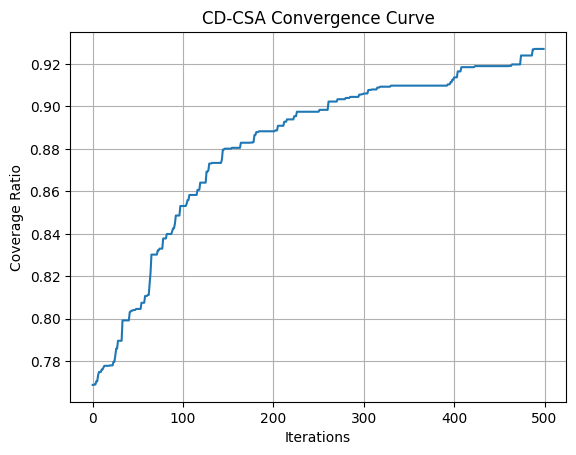

In [1]:

import numpy as np
import matplotlib.pyplot as plt
import time

# ==========================================
# WSN COVERAGE PARAMETERS
# ==========================================

AREA = 100
NUM_NODES = 40
SENSING_RADIUS = 10
COMM_RADIUS = 20

NESTS = 25
MAX_ITER = 500
PA = 0.25

# ==========================================
# NETWORK INITIALIZATION
# ==========================================

np.random.seed(42)

initial_nodes = np.random.uniform(
    0, AREA, (NUM_NODES, 2)
)

# Grid for coverage calculation
grid_x, grid_y = np.meshgrid(
    np.linspace(0, AREA, 100),
    np.linspace(0, AREA, 100)
)

grid = np.column_stack((
    grid_x.ravel(), grid_y.ravel()
))


# ==========================================
# COVERAGE FITNESS FUNCTION
# ==========================================

def coverage_fitness(nodes):

    distances = np.linalg.norm(
        grid[:, None, :] - nodes[None, :, :],
        axis=2
    )

    covered = np.any(
        distances <= SENSING_RADIUS,
        axis=1
    )

    return np.mean(covered)


# ==========================================
# CAUCHY DISTRIBUTION
# ==========================================

def cauchy_mutation():

    return np.random.standard_cauchy(
        size=(NUM_NODES, 2)
    )


# ==========================================
# IMPROVED CUCKOO SEARCH
# ==========================================

def cd_csa():

    nests = np.random.uniform(
        0, AREA, (NESTS, NUM_NODES, 2)
    )

    fitness = np.array([
        coverage_fitness(n) for n in nests
    ])

    best_index = np.argmax(fitness)

    best_nest = nests[best_index].copy()
    best_fitness = fitness[best_index]

    convergence = []

    for iteration in range(MAX_ITER):

        worst_fitness = np.min(fitness)

        # Average distance from current nests
        # to the best nest
        distances = np.linalg.norm(
            nests - best_nest, axis=(1, 2)
        )

        avg_distance = np.mean(distances)

        # Adaptive step size
        step = 1.0 / (1.0 + avg_distance / AREA)

        for i in range(NESTS):

            # Gradient-inspired adaptive movement
            direction = best_nest - nests[i]

            candidate = (
                nests[i]
                + step * 0.1 * direction
                + step * np.random.normal(
                    0, 1, (NUM_NODES, 2)
                )
            )

            # Fitness before mutation
            old_fitness = fitness[i]

            # Cauchy mutation intensity
            gamma = 0.01 + 0.1 * (
                old_fitness - worst_fitness
            )

            candidate += (
                gamma * cauchy_mutation()
            )

            candidate = np.clip(
                candidate, 0, AREA
            )

            new_fitness = coverage_fitness(
                candidate
            )

            if new_fitness > fitness[i]:

                nests[i] = candidate
                fitness[i] = new_fitness

        # Abandon worst nests
        abandon_count = max(
            1, int(PA * NESTS)
        )

        worst_indices = np.argsort(
            fitness
        )[:abandon_count]

        nests[worst_indices] = np.random.uniform(
            0, AREA,
            (abandon_count, NUM_NODES, 2)
        )

        for i in worst_indices:

            fitness[i] = coverage_fitness(
                nests[i]
            )

        # Update global best
        best_index = np.argmax(fitness)

        if fitness[best_index] > best_fitness:

            best_fitness = fitness[best_index]
            best_nest = nests[best_index].copy()

        convergence.append(best_fitness)

        if (iteration + 1) % 50 == 0:

            print(
                f"CD-CSA Iteration: {iteration+1}, "
                f"Coverage: {best_fitness*100:.2f}%"
            )

    return best_nest, best_fitness, convergence


# ==========================================
# COVERAGE VISUALIZATION
# ==========================================

def plot_coverage(nodes):

    plt.figure(figsize=(8, 7))

    plt.scatter(
        nodes[:, 0],
        nodes[:, 1],
        color='red',
        marker='o',
        label='Sensor Nodes'
    )

    for node in nodes:

        circle = plt.Circle(
            node,
            SENSING_RADIUS,
            color='blue',
            alpha=0.08
        )

        plt.gca().add_patch(circle)

    plt.xlim(0, AREA)
    plt.ylim(0, AREA)

    plt.title("Optimized WSN Sensor Coverage")
    plt.xlabel("X Coordinate (m)")
    plt.ylabel("Y Coordinate (m)")

    plt.grid()
    plt.legend()
    plt.axis("equal")
    plt.show()


# ==========================================
# EXECUTE COVERAGE OPTIMIZATION
# ==========================================

start = time.time()

optimized_nodes, coverage, convergence = cd_csa()

execution_time = time.time() - start

print("\n========== COVERAGE RESULTS ==========")

print("Initial Coverage:",
      coverage_fitness(initial_nodes) * 100, "%")

print("Optimized Coverage:",
      coverage * 100, "%")

print("Execution Time:", execution_time, "seconds")

plot_coverage(optimized_nodes)

plt.plot(convergence)
plt.xlabel("Iterations")
plt.ylabel("Coverage Ratio")
plt.title("CD-CSA Convergence Curve")
plt.grid()
plt.show()
